# 04. Strojenie hiperparametrów (Optuna)

Stroimy najlepszą architekturę z notatnika 03 - **ResNet50**.

**Jak działa Optuna** (wykład 4): definiujemy przestrzeń hiperparametrów i funkcję celu;
próbnik **TPE** (Tree-structured Parzen Estimator, odmiana optymalizacji bayesowskiej) buduje
z dotychczasowych prób dwa rozkłady - dla dobrych i słabych konfiguracji - i proponuje punkty,
w których stosunek tych rozkładów jest największy. **MedianPruner** przerywa próbę, gdy jej
wynik po kolejnym foldzie jest gorszy od mediany wcześniejszych prób na tym samym etapie
(odmiana idei Successive Halving: nie tracimy czasu na słabe konfiguracje).

Przestrzeń (`src/tune.py`):
| hiperparametr | zakres |
|---|---|
| LR głowicy | 1e-4 - 3e-3 (skala log.) |
| weight decay | 1e-6 - 1e-2 (skala log.) |
| dropout | 0 - 0.5 |
| batch size | 16, 32, 64 |
| liczba odmrożonych bloków | 1 - wszystkie |

Funkcja celu: **średnie macro-F1 na foldach walidacyjnych 0-2** (10 epok na próbę, żeby
zmieścić się w czasie). Zbiór testowy nie jest używany. Uruchomienie w tle:
`python -m src.tune --model resnet50 --trials 20` (ok. 6 minut na próbę na RTX 4060).

Strojenie zostało przerwane po 16 próbach (komputer się wyłączył). Ponieważ Optuna zapisuje
każdą próbę w bazie SQLite, po wznowieniu przerwaną próbę oznaczyliśmy jako nieudaną (`FAIL`)
i dokończyliśmy badanie do 20 zakończonych lub przyciętych prób.

In [1]:
import sys
sys.path.insert(0, '..')

import json

import matplotlib.pyplot as plt
import optuna
import pandas as pd

from src.data import FIG_DIR, METRICS_DIR, OUT_DIR

MODEL = 'resnet50'
study = optuna.load_study(study_name=f'tune_{MODEL}', storage=f'sqlite:///{OUT_DIR / "optuna.db"}')
trials = study.trials_dataframe()
print('próby:', len(trials), '| zakończone:', (trials.state == 'COMPLETE').sum(),
      '| przycięte:', (trials.state == 'PRUNED').sum(), '| przerwane:', (trials.state == 'FAIL').sum())
print('najlepsze macro-F1 (walidacja):', round(study.best_value, 4))
study.best_params

próby: 21 | zakończone: 14 | przycięte: 6 | przerwane: 1
najlepsze macro-F1 (walidacja): 0.9923


{'lr': 0.002238524977410612,
 'weight_decay': 0.0014766762447965915,
 'dropout': 0.11600335563585339,
 'batch_size': 16,
 'n_unfreeze': 3}

In [2]:
cols = ['number', 'value', 'state'] + [c for c in trials.columns if c.startswith('params_')]
trials[cols].sort_values('value', ascending=False).round(5).head(10)

,number,value,state,params_batch_size,params_dropout,params_lr,params_n_unfreeze,params_weight_decay
15,15,0.99232,COMPLETE,16,0.11600,0.00224,3,0.00148
13,13,0.98927,COMPLETE,16,0.13715,0.00250,4,0.00032
17,17,0.98923,COMPLETE,16,0.15515,0.00143,4,0.00210
19,19,0.98866,COMPLETE,16,0.06635,0.00286,5,0.00055
14,14,0.98812,COMPLETE,16,0.05074,0.00291,3,0.00010
5,5,0.98775,COMPLETE,16,0.04884,0.00156,3,0.00002
20,20,0.98741,COMPLETE,16,0.18192,0.00281,5,0.00002
12,12,0.98657,COMPLETE,32,0.25043,0.00167,3,0.00019
1,1,0.98408,COMPLETE,32,0.35404,0.00190,2,0.00025
10,10,0.98282,COMPLETE,16,0.08653,0.00064,3,0.00001


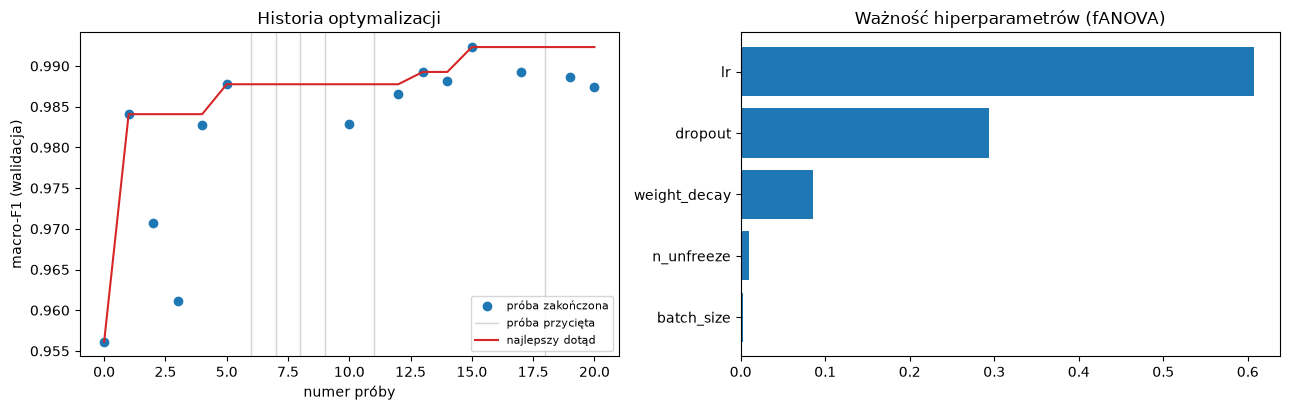

{'lr': 0.6077327021345382,
 'dropout': 0.29343507437672867,
 'weight_decay': 0.08535375930952176,
 'n_unfreeze': 0.010177505215067476,
 'batch_size': 0.0033009589641438976}

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
done = trials[trials.state == 'COMPLETE']
axes[0].scatter(done.number, done.value, label='próba zakończona')
for i, n in enumerate(trials[trials.state == 'PRUNED'].number):
    axes[0].axvline(n, color='lightgray', lw=1, zorder=0, label='próba przycięta' if i == 0 else None)
axes[0].plot(done.number, done.value.cummax(), color='tab:red', label='najlepszy dotąd')
axes[0].set_xlabel('numer próby')
axes[0].set_ylabel('macro-F1 (walidacja)')
axes[0].set_title('Historia optymalizacji')
axes[0].legend(fontsize=8)
importance = optuna.importance.get_param_importances(study)
axes[1].barh(list(importance)[::-1], list(importance.values())[::-1])
axes[1].set_title('Ważność hiperparametrów (fANOVA)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'optuna.png', dpi=150)
plt.show()
json.dump(importance, open(METRICS_DIR / f'optuna_{MODEL}_importance.json', 'w'), indent=1)
importance

## Pełna walidacja krzyżowa z najlepszymi parametrami
Z najlepszymi parametrami powtarzamy walidację na wszystkich 5 foldach i pełnych 15 epokach
(`python -m src.train cv --model resnet50 --params out/metrics/optuna_resnet50_best.json --tag resnet50_tuned`).

In [4]:
def cv_table(tag):
    cv = json.load(open(METRICS_DIR / f'cv_{tag}.json'))
    folds = pd.DataFrame([{k: v for k, v in f.items() if k != 'history'} for f in cv['folds']])
    return folds[['accuracy', 'macro_f1', 'macro_recall', 'macro_specificity', 'macro_auc']].agg(['mean', 'std']).T

pd.concat({'domyślne': cv_table(MODEL), 'po strojeniu': cv_table(f'{MODEL}_tuned')}, axis=1).round(4)

domyślne         po strojeniu        
                      mean     std         mean     std
accuracy            0.9842  0.0045       0.9867  0.0064
macro_f1            0.9840  0.0045       0.9865  0.0065
macro_recall        0.9841  0.0045       0.9866  0.0064
macro_specificity   0.9948  0.0015       0.9956  0.0021
macro_auc           0.9990  0.0003       0.9994  0.0004

## Interpretacja i ryzyko przeoptymalizowania
- Badanie liczy 20 prób (14 zakończonych, 6 przyciętych przez MedianPruner) oraz jedną przerwaną.
  Najlepsza okazała się próba 15: LR 2,2e-3, weight decay 1,5e-3, dropout 0,12, batch 16
  i 3 odmrożone bloki (`layer2`-`layer4`).
- Według fANOVA najważniejszy jest LR (ok. 0,6 ważności), potem dropout; batch size i liczba
  odmrożonych bloków mają mały wpływ. Wszystkie najlepsze próby mają LR powyżej 1e-3 i batch 16.
- Wynik walidacji najlepszej próby (0,992) jest **zawyżony**. Wybieramy maksimum z 20 prób
  liczonych na tych samych 3 foldach, więc część przewagi to szczęście tej konfiguracji na tych
  foldach (przeoptymalizowanie na walidacji, wykład 4). Dodatkowo w każdym foldzie wybieramy
  najlepszą epokę.
- W pełnej 5-krotnej walidacji parametry po strojeniu dają macro-F1 0,9865 ± 0,0065 wobec
  0,9840 ± 0,0045 dla domyślnych. Poprawa jest mniejsza niż odchylenie między foldami, a foldy
  0-2 były użyte do strojenia, więc i ta liczba jest lekko optymistyczna. Poprawną metodą byłaby
  zagnieżdżona walidacja krzyżowa (5 razy droższa). Ostatecznym sprawdzianem jest test,
  którego strojenie nie widziało (notatnik 05).